# **Genomic analysis of malaria vectors in The Gambia**

### **Pyrethroid target-site resistance**


- In this notebook, compute and visualise frequencies of non-synonymous SNPs within the Vgsc gene for the chosen cohorts.

### **Metabolic resistance**


- Further, we compute and visualise the frequencies of CNVs in known metabolic gene classes for the chosen cohorts.


In [ ]:
!pip install -q malariagen_data

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 91.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 205.1/205.1 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.7/71.7 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 65.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 79.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.9/775.9 kB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 83.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 73.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.3/211.3 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 72.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB

In [ ]:
import malariagen_data
import plotly.express as px
import pandas as pd

In [ ]:
ag3 = malariagen_data.Ag3()
ag3

<MalariaGEN Ag3 API client>
Storage URL             : gs://vo_agam_release_master_us_central1/
Data releases available : 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 3.10, 3.11, 3.12, 3.13, 3.14
Results cache           : None
Cohorts analysis        : 20250815
AIM analysis            : 20220528
Site filters analysis   : dt_20200416
Software version        : malariagen_data 15.4.0
Client location         : District of Columbia, United States (Google Cloud us-other)
---
Please note that data are subject to terms of use,
for more information see https://www.malariagen.net/data
or contact support@malariagen.net. For API documentation see 
https://malariagen.github.io/malariagen-data-python/v15.4.0/Ag3.html

In [ ]:
gambia_sample_query = "country == 'Gambia, The' and sample_set == '1272-VO-GM-OPONDO-VMF00160'"

In [ ]:
# access metadata
df_samples_gambia = ag3.sample_metadata(sample_query=gambia_sample_query)
df_samples_gambia

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
0,VBS47721-6366STDY9854330,C1161,Kevin Opondo,"Gambia, The",Jareng,2019,9,13.620,-15.190,F,...,Janjanbureh,GM-M,Niamina East,coluzzii,GM-M_colu_2019,GM-M_colu_2019_09,GM-M_colu_2019_Q3,GM-M_Niamina-East_colu_2019,GM-M_Niamina-East_colu_2019_09,GM-M_Niamina-East_colu_2019_Q3
1,VBS47723-6366STDY9854332,C0454,Kevin Opondo,"Gambia, The",Dongoroba,2019,9,13.380,-15.294,F,...,Mansakonko,GM-L,Jarra East,arabiensis,GM-L_arab_2019,GM-L_arab_2019_09,GM-L_arab_2019_Q3,GM-L_Jarra-East_arab_2019,GM-L_Jarra-East_arab_2019_09,GM-L_Jarra-East_arab_2019_Q3
2,VBS47724-6366STDY9854333,C2526,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,unassigned,NaN,NaN,NaN,NaN,NaN,NaN
3,VBS47725-6366STDY9854334,C2409,Kevin Opondo,"Gambia, The",Kerewan,2019,9,13.515,-14.896,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_09,GM-M_Lower-Fuladu-West_arab_2019_Q3
4,VBS47726-6366STDY9854335,C0587,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
377,VBS48172-6366STDY9854773,W2393,Kevin Opondo,"Gambia, The",Bullock,2019,9,13.181,-16.414,F,...,Brikama,GM-W,Foni Brefet,bissau,GM-W_biss_2019,GM-W_biss_2019_09,GM-W_biss_2019_Q3,GM-W_Foni-Brefet_biss_2019,GM-W_Foni-Brefet_biss_2019_09,GM-W_Foni-Brefet_biss_2019_Q3
378,VBS48173-6366STDY9854774,W0382,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
379,VBS48174-6366STDY9854775,W1168,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
380,VBS48175-6366STDY9854776,W1807,Kevin Opondo,"Gambia, The",Brikama-A,2019,9,13.290,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3


### **Pyrethroid target-site resistance**

- Vgsc gene target-site resistance

In [ ]:
df_samples_gambia.pivot_table(
    index=["admin1_name", "admin2_name", "year"],
    columns="taxon",
    values="sample_id",
    aggfunc="count",
    fill_value=0,
)

taxon                               arabiensis  bissau  coluzzii  gambiae  \
admin1_name admin2_name       year                                          
Basse       Basse             2019          28       0         3        4   
            Jimara            2019          37       1         3       10   
            Sandu             2019           8       0         1        2   
            Tumana            2019          21       0         0        0   
            Wuli East         2019           1       0         0        0   
Brikama     Foni Brefet       2019           1       4         0        0   
            Kombo Central     2019          28       0         0        0   
Janjanbureh Lower Fuladu West 2019          51       0        12        1   
            Niamina Dankunku  2019           0       1         0        0   
            Niamina East      2019          10       0         6        0   
            Niamina West      2019           8       0         1        2   
            Upper Fuladu West 2019          12       0         4        0   
Kanifing    Bakau             2019           6       0         0        0   
            Jeshwang          2019          77       0         0        0   
Kerewan     Illiasa           2019           3       0         0        0   
            Lower Niumi       2019          13       0         0        0   
Kuntaur     Niani             2019           4       0         4        0   
Mansakonko  Jarra East        2001           1       0         0        0   
                              2019           6       0         3        0   

taxon                               unassigned  
admin1_name admin2_name       year              
Basse       Basse             2019           1  
            Jimara            2019           1  
            Sandu             2019           0  
            Tumana            2019           1  
            Wuli East         2019           0  
Brikama     Foni Brefet       2019           0  
            Kombo Central     2019           0  
Janjanbureh Lower Fuladu West 2019           0  
            Niamina Dankunku  2019           0  
            Niamina East      2019           1  
            Niamina West      2019           0  
            Upper Fuladu West 2019           1  
Kanifing    Bakau             2019           0  
            Jeshwang          2019           0  
Kerewan     Illiasa           2019           0  
            Lower Niumi       2019           0  
Kuntaur     Niani             2019           0  
Mansakonko  Jarra East        2001           0  
                              2019           0

In [ ]:
df_vgsc_freq_gambia = ag3.aa_allele_frequencies(
    transcript="AGAP004707-RD",
    sample_query=gambia_sample_query,
    cohorts="admin2_year",
)
df_vgsc_freq_gambia

Load SNP genotypes:   0%|          | 0/79 [00:00<?, ?it/s]

Compute allele frequencies:   0%|          | 0/11 [00:00<?, ?it/s]

Compute SNP effects:   0%|          | 0/22573 [00:00<?, ?it/s]

,,,frq_GM-M_Lower-Fuladu-West_arab_2019,frq_GM-M_Lower-Fuladu-West_colu_2019,frq_GM-M_Niamina-East_arab_2019,frq_GM-M_Upper-Fuladu-West_arab_2019,frq_GM-N_Lower-Niumi_arab_2019,frq_GM-U_Basse_arab_2019,frq_GM-U_Jimara_arab_2019,frq_GM-U_Jimara_gamb_2019,frq_GM-U_Tumana_arab_2019,frq_GM-W_Jeshwang_arab_2019,...,transcript,aa_pos,ref_allele,ref_aa,alt_aa,effect,impact,alt_allele,max_af,label
aa_change,contig,position,,,,,,,,,,,,,,,,,,,,,
M1I,2L,2358160,0.009804,0.0,0.00,0.0,0.000000,0.0,0.0,0.0,0.00000,0.000000,...,AGAP004707-RD,1.0,G,M,I,NON_SYNONYMOUS_CODING,MODERATE,T,0.009804,"M1I (2L:2,358,160 G>T)"
D6Y,2L,2358173,0.000000,0.0,0.05,0.0,0.000000,0.0,0.0,0.0,0.00000,0.000000,...,AGAP004707-RD,6.0,G,D,Y,NON_SYNONYMOUS_CODING,MODERATE,T,0.050000,"D6Y (2L:2,358,173 G>T)"
E12*,2L,2358191,0.000000,0.0,0.00,0.0,0.038462,0.0,0.0,0.0,0.00000,0.000000,...,AGAP004707-RD,12.0,G,E,*,STOP_GAINED,HIGH,T,0.038462,"E12* (2L:2,358,191 G>T)"
F16L,2L,2358205,0.009804,0.0,0.00,0.0,0.000000,0.0,0.0,0.0,0.00000,0.000000,...,AGAP004707-RD,16.0,C,F,L,NON_SYNONYMOUS_CODING,MODERATE,A,0.009804,"F16L (2L:2,358,205 C>A)"
R17S,2L,2358206,0.019608,0.0,0.00,0.0,0.038462,0.0,0.0,0.0,0.00000,0.000000,...,AGAP004707-RD,17.0,C,R,S,NON_SYNONYMOUS_CODING,MODERATE,A,0.038462,"R17S (2L:2,358,206 C>A)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
V2103F,2L,2431567,0.000000,0.0,0.00,0.0,0.000000,0.0,0.0,0.0,0.02381,0.000000,...,AGAP004707-RD,2103.0,G,V,F,NON_SYNONYMOUS_CODING,MODERATE,T,0.023810,"V2103F (2L:2,431,567 G>T)"
H2105Y,2L,2431573,0.009804,0.0,0.00,0.0,0.000000,0.0,0.0,0.0,0.00000,0.000000,...,AGAP004707-RD,2105.0,C,H,Y,NON_SYNONYMOUS_CODING,MODERATE,T,0.009804,"H2105Y (2L:2,431,573 C>T)"
S2108T,2L,2431582,0.009804,0.0,0.00,0.0,0.000000,0.0,0.0,0.0,0.00000,0.006494,...,AGAP004707-RD,2108.0,T,S,T,NON_SYNONYMOUS_CODING,MODERATE,A,0.009804,"S2108T (2L:2,431,582 T>A)"


In [ ]:
ag3.plot_frequencies_heatmap(
    df_vgsc_freq_gambia.query("max_af > 0.05")
)

In [ ]:
df_vgsc_freq_gambia_admin2_year = (
    df_samples_gambia
    .groupby("cohort_admin2_year")
    .aggregate({
        "latitude": "mean",
        "longitude": "mean",
        "sample_id": "count",
    })
    .query("sample_id >= 10")
    .sort_values("longitude")
)
df_vgsc_freq_gambia_admin2_year

,latitude,longitude,sample_id
cohort_admin2_year,,,
GM-W_Jeshwang_arab_2019,13.437247,-16.670987,77
GM-W_Kombo-Central_arab_2019,13.290000,-16.657000,28
GM-N_Lower-Niumi_arab_2019,13.481000,-16.515000,13
GM-M_Niamina-East_arab_2019,13.619500,-15.157000,10
GM-M_Lower-Fuladu-West_colu_2019,13.542333,-14.910500,12
GM-M_Lower-Fuladu-West_arab_2019,13.530882,-14.902039,51
GM-M_Upper-Fuladu-West_arab_2019,13.434000,-14.655000,12
GM-U_Jimara_arab_2019,13.275973,-14.324162,37
GM-U_Jimara_gamb_2019,13.264600,-14.306400,10


In [ ]:
all_cohorts_admin2_year = df_vgsc_freq_gambia_admin2_year.index.tolist()
all_cohorts_admin2_year

['GM-W_Jeshwang_arab_2019',
 'GM-W_Kombo-Central_arab_2019',
 'GM-N_Lower-Niumi_arab_2019',
 'GM-M_Niamina-East_arab_2019',
 'GM-M_Lower-Fuladu-West_colu_2019',
 'GM-M_Lower-Fuladu-West_arab_2019',
 'GM-M_Upper-Fuladu-West_arab_2019',
 'GM-U_Jimara_arab_2019',
 'GM-U_Jimara_gamb_2019',
 'GM-U_Basse_arab_2019',
 'GM-U_Tumana_arab_2019']

In [ ]:
ag3.plot_frequencies_heatmap(
    df_vgsc_freq_gambia.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in all_cohorts_admin2_year]]
)

In [ ]:
frequency_columns = [
    col for col in df_vgsc_freq_gambia.columns
    if col.startswith("frq_")
]
frequency_columns

NameError: name 'df_vgsc_freq_gambia' is not defined

In [ ]:
vgsc_aa_effect_df = df_vgsc_freq_gambia[["effect", "impact"]]
vgsc_aa_effect_df

,,,effect,impact
aa_change,contig,position,,
M1I,2L,2358160,NON_SYNONYMOUS_CODING,MODERATE
D6Y,2L,2358173,NON_SYNONYMOUS_CODING,MODERATE
E12*,2L,2358191,STOP_GAINED,HIGH
F16L,2L,2358205,NON_SYNONYMOUS_CODING,MODERATE
R17S,2L,2358206,NON_SYNONYMOUS_CODING,MODERATE
...,...,...,...,...
V2103F,2L,2431567,NON_SYNONYMOUS_CODING,MODERATE
H2105Y,2L,2431573,NON_SYNONYMOUS_CODING,MODERATE
S2108T,2L,2431582,NON_SYNONYMOUS_CODING,MODERATE


In [ ]:
ds_vgsc_aa_gambia = ag3.aa_allele_frequencies_advanced(
    transcript="AGAP004707-RD",
    area_by="admin1_name",
    period_by="year",
    sample_query=gambia_sample_query,
    variant_query="max_af > 0.05"
)
ds_vgsc_aa_gambia

Load SNP genotypes:   0%|          | 0/79 [00:00<?, ?it/s]

Compute SNP allele frequencies:   0%|          | 0/7 [00:00<?, ?it/s]

Compute SNP effects:   0%|          | 0/24653 [00:00<?, ?it/s]

<xarray.Dataset> Size: 5kB
Dimensions:                 (cohorts: 7, variants: 11)
Dimensions without coordinates: cohorts, variants
Data variables: (12/31)
    cohort_area             (cohorts) object 56B 'Basse' 'Brikama' ... 'Basse'
    cohort_label            (cohorts) object 56B 'Basse_arab_2019' ... 'Basse...
    cohort_lat_max          (cohorts) float64 56B 13.47 13.29 ... 13.62 13.43
    cohort_lat_mean         (cohorts) float64 56B 13.31 13.29 ... 13.55 13.28
    cohort_lat_min          (cohorts) float64 56B 13.24 13.18 ... 13.43 13.24
    cohort_lon_max          (cohorts) float64 56B -13.98 -16.41 ... -14.65 -14.2
    ...                      ...
    variant_label           (variants) object 88B 'T664S (2L:2,407,792 A>T)' ...
    variant_max_af          (variants) float64 88B 0.3793 0.0625 ... 0.06522
    variant_position        (variants) int32 44B 2407792 2408117 ... 2431330
    variant_ref_aa          (variants) object 88B 'T' 'H' 'T' ... 'I' 'P' 'T'
    variant_ref_allele      (variants) object 88B 'A' 'C' 'C' ... 'T' 'C' 'A'
    variant_transcript      (variants) object 88B 'AGAP004707-RD' ... 'AGAP00...
Attributes:
    title:    AGAP004707-RD (Vgsc/para) SNP frequencies

In [ ]:
ag3.plot_frequencies_time_series(
    ds_vgsc_aa_gambia,
    height=1500)

In [ ]:
arab_cohorts_admin2_year_gambia = (
    df_samples_gambia
    .query("taxon == 'arabiensis'")
    .groupby("cohort_admin2_year")
    .aggregate({
        "latitude": "mean",
        "longitude": "mean",
        "sample_id": "count",
    })
    .query("sample_id >= 10")
    .sort_values("longitude")
)
arab_cohorts_admin2_year_gambia

,latitude,longitude,sample_id
cohort_admin2_year,,,
GM-W_Jeshwang_arab_2019,13.437247,-16.670987,77
GM-W_Kombo-Central_arab_2019,13.290000,-16.657000,28
GM-N_Lower-Niumi_arab_2019,13.481000,-16.515000,13
GM-M_Niamina-East_arab_2019,13.619500,-15.157000,10
GM-M_Lower-Fuladu-West_arab_2019,13.530882,-14.902039,51
GM-M_Upper-Fuladu-West_arab_2019,13.434000,-14.655000,12
GM-U_Jimara_arab_2019,13.275973,-14.324162,37
GM-U_Basse_arab_2019,13.269286,-14.205750,28
GM-U_Tumana_arab_2019,13.355952,-14.049190,21


In [ ]:
arab_cohorts_admin2_year = arab_cohorts_admin2_year_gambia.index.tolist()
arab_cohorts_admin2_year

['GM-W_Jeshwang_arab_2019',
 'GM-W_Kombo-Central_arab_2019',
 'GM-N_Lower-Niumi_arab_2019',
 'GM-M_Niamina-East_arab_2019',
 'GM-M_Lower-Fuladu-West_arab_2019',
 'GM-M_Upper-Fuladu-West_arab_2019',
 'GM-U_Jimara_arab_2019',
 'GM-U_Basse_arab_2019',
 'GM-U_Tumana_arab_2019']

In [ ]:
ag3.plot_frequencies_heatmap(
    df_vgsc_freq_gambia.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in arab_cohorts_admin2_year]]
)

#### **Pyrethroid target-site resistance in gambiae and coluzzii**

In [ ]:
df_gambcolu_cohorts_admin2_year = (
    df_samples_gambia
    .query("taxon != 'arabiensis'")
    .groupby("cohort_admin2_year")
    .aggregate({
        "latitude": "mean",
        "longitude": "mean",
        "sample_id": "count",
        "taxon": "first",
    })
    .query("sample_id >= 10")
    .sort_values("taxon")
)
df_gambcolu_cohorts_admin2_year

,latitude,longitude,sample_id,taxon
cohort_admin2_year,,,,
GM-U_Jimara_gamb_2019,13.264600,-14.3064,10,gambiae
GM-N_Central-Badibu_gcx1_2011,13.550000,-15.9000,68,gcx1
GM-L_Kiang-West_gcx2_2006,13.417000,-16.0330,19,gcx2
GM-M_Lower-Fuladu-West_gcx2_2012,13.567000,-14.9170,172,gcx2
GM-M_Lower-Fuladu-West_gcx2_2019,13.542333,-14.9105,12,gcx2


In [ ]:
gambcolu_cohorts_admin2_year = df_gambcolu_cohorts_admin2_year.index.tolist()
gambcolu_cohorts_admin2_year

['GM-U_Jimara_gamb_2019',
 'GM-N_Central-Badibu_gcx1_2011',
 'GM-L_Kiang-West_gcx2_2006',
 'GM-M_Lower-Fuladu-West_gcx2_2012',
 'GM-M_Lower-Fuladu-West_gcx2_2019']

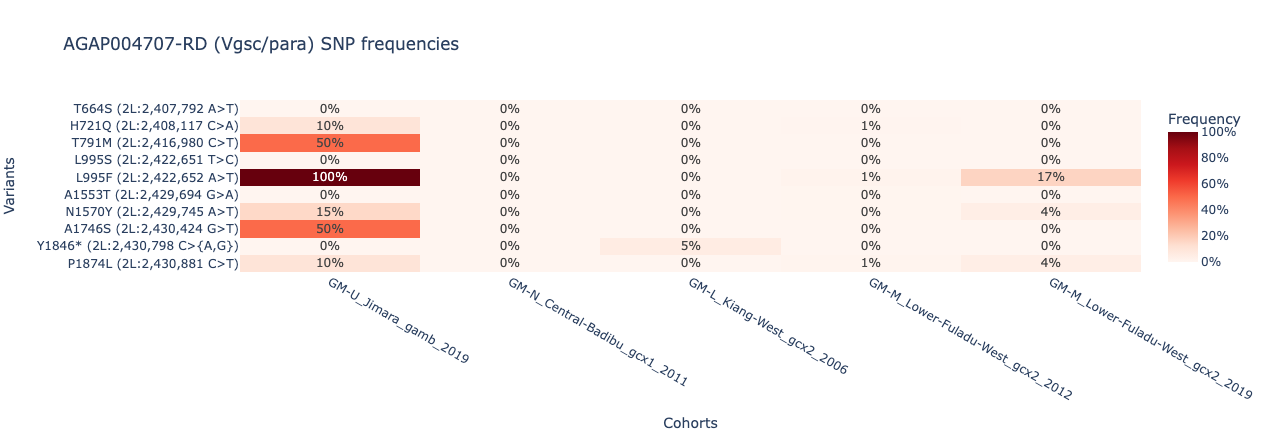

In [ ]:
ag3.plot_frequencies_heatmap(
    df_vgsc_freq_gambia.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in gambcolu_cohorts_admin2_year]]
)

### **Metabolic Resistance**

#### **Cyp P450**

- CNV freq across different species

In [ ]:
keap1 = "2R:40,926,195-40,945,169"
cyp6aap_region = "2R:28,480,000-28,510,000"
cyp9k1_region = "X:15,240,000-15,250,000"
cyp6mz_region = "3R:6,924,000-6,980,000"
cohorts = "admin2_year"
sample_sets = ["AG1000G-GM-A", "AG1000G-GM-B", "AG1000G-GM-C", "1272-VO-GM-OPONDO-VMF00160"]

In [ ]:
gst_region = "3R:28,597,000-28,600,000"
ace1_region = "2R:3,300,000-4,000,000"
ace_region = "2R:3,483,099-3,497,400"

In [ ]:
df_samples_gambia['release'].unique()

array(['3.5'], dtype=object)

In [ ]:
ag3.sample_sets(release=['3.0', '3.5'])

,sample_set,sample_count,study_id,study_url,terms_of_use_expiry_date,terms_of_use_url,release,unrestricted_use
0,AG1000G-AO,81,AG1000G-AO,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0,True
1,AG1000G-BF-A,181,AG1000G-BF-1,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0,True
2,AG1000G-BF-B,102,AG1000G-BF-1,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0,True
3,AG1000G-BF-C,13,AG1000G-BF-2,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0,True
4,AG1000G-CD,76,AG1000G-CD,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0,True
5,AG1000G-CF,73,AG1000G-CF,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0,True
6,AG1000G-CI,80,AG1000G-CI,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0,True
7,AG1000G-CM-A,303,AG1000G-CM-1,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0,True
8,AG1000G-CM-B,97,AG1000G-CM-2,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0,True
9,AG1000G-CM-C,44,AG1000G-CM-3,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0,True


In [ ]:
cnv_freqs_df_gambia = ag3.gene_cnv_frequencies(
    sample_query=gambia_sample_query,
    region=[keap1,cyp6aap_region,cyp9k1_region,cyp6mz_region, gst_region, ace_region],
    cohorts=cohorts,
    sample_sets=sample_sets,
    drop_invariant=False,
    )
cnv_freqs_df_gambia

Load CNV HMM data:   0%|          | 0/54 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/1 [00:00<?, ?it/s]

Load CNV HMM data:   0%|          | 0/54 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/11 [00:00<?, ?it/s]

Load CNV HMM data:   0%|          | 0/54 [00:00<?, ?it/s]

...

Load CNV HMM data:   0%|          | 0/54 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/2 [00:00<?, ?it/s]

Load CNV HMM data:   0%|          | 0/54 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/1 [00:00<?, ?it/s]

gene_strand  \
gene_id    gene_name cnv_type               
AGAP003645 NaN       amp                -   
                     del                -   
AGAP002859 NaN       amp                +   
                     del                +   
AGAP002862 CYP6AA1   amp                -   
                     del                -   
AGAP013128 CYP6AA2   amp                -   
                     del                -   
AGAP002863 COEAE6O   amp                -   
                     del                -   
AGAP002864 CYP6P15P  amp                -   
                     del                -   
AGAP002865 CYP6P3    amp                -   
                     del                -   
AGAP002866 CYP6P5    amp                -   
                     del                -   
AGAP002867 CYP6P4    amp                -   
                     del                -   
AGAP002868 CYP6P1    amp                -   
                     del                -   
AGAP002869 CYP6P2    amp                -   
                     del                -   
AGAP002870 CYP6AD1   amp                -   
                     del                -   
AGAP000818 CYP9K1    amp                -   
                     del                -   
AGAP008212 CYP6M2    amp                +   
                     del                +   
AGAP008213 CYP6M3    amp                +   
                     del                +   
AGAP008214 CYP6M4    amp                +   
                     del                +   
AGAP013724 SG7c      amp                -   
                     del                -   
AGAP008215 SG7b      amp                -   
                     del                -   
AGAP008216 SG7       amp                -   
                     del                -   
AGAP008217 CYP6Z3    amp                -   
                     del                -   
AGAP008218 CYP6Z2    amp                -   
                     del                -   
AGAP008219 CYP6Z1    amp                -   
                     del                -   
AGAP009194 GSTE2     amp                -   
                     del                -   
AGAP009195 GSTE1     amp                -   
                     del                -   
AGAP001356 ACE1      amp                +   
                     del                +   

                                                                gene_description  \
gene_id    gene_name cnv_type                                                      
AGAP003645 NaN       amp       kelch-like protein 19 [Source:VB Community Ann...   
                     del       kelch-like protein 19 [Source:VB Community Ann...   
AGAP002859 NaN       amp       solute carrier family 8 (sodium/calcium exchan...   
                     del       solute carrier family 8 (sodium/calcium exchan...   
AGAP002862 CYP6AA1   amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP013128 CYP6AA2   amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002863 COEAE6O   amp       carboxylesterase alpha esterase [Source:VB Com...   
                     del       carboxylesterase alpha esterase [Source:VB Com...   
AGAP002864 CYP6P15P  amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002865 CYP6P3    amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002866 CYP6P5    amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002867 CYP6P4    amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP00286

In [ ]:
df_cnv_gambia_cohorts = (
    df_samples_gambia
    .groupby("cohort_admin2_year")
    .aggregate({
        "latitude":"mean",
        "longitude":"mean",
        "sample_id":"count",
        "taxon":"first"
    })
    .query("sample_id>=10")
    .sort_values("longitude")
)
df_cnv_gambia_cohorts

,latitude,longitude,sample_id,taxon
cohort_admin2_year,,,,
GM-W_Jeshwang_arab_2019,13.437247,-16.670987,77,arabiensis
GM-W_Kombo-Central_arab_2019,13.290000,-16.657000,28,arabiensis
GM-N_Lower-Niumi_arab_2019,13.481000,-16.515000,13,arabiensis
GM-M_Niamina-East_arab_2019,13.619500,-15.157000,10,arabiensis
GM-M_Lower-Fuladu-West_colu_2019,13.542333,-14.910500,12,coluzzii
GM-M_Lower-Fuladu-West_arab_2019,13.530882,-14.902039,51,arabiensis
GM-M_Upper-Fuladu-West_arab_2019,13.434000,-14.655000,12,arabiensis
GM-U_Jimara_arab_2019,13.275973,-14.324162,37,arabiensis
GM-U_Jimara_gamb_2019,13.264600,-14.306400,10,gambiae


In [ ]:
df_cnv_gm_cohorts = df_cnv_gambia_cohorts.index.tolist()
df_cnv_gm_cohorts

['GM-W_Jeshwang_arab_2019',
 'GM-W_Kombo-Central_arab_2019',
 'GM-N_Lower-Niumi_arab_2019',
 'GM-M_Niamina-East_arab_2019',
 'GM-M_Lower-Fuladu-West_colu_2019',
 'GM-M_Lower-Fuladu-West_arab_2019',
 'GM-M_Upper-Fuladu-West_arab_2019',
 'GM-U_Jimara_arab_2019',
 'GM-U_Jimara_gamb_2019',
 'GM-U_Basse_arab_2019',
 'GM-U_Tumana_arab_2019']

In [ ]:
# frq_GM-M_Lower-Fuladu-West_arab_2019
# frq_GM-M_Lower-Fuladu-West_gcx2_2012
# frq_GM-N_Central-Badibu_gcx1_2011
# frq_GM-U_Basse_arab_2019
# frq_GM-U_Jimara_arab_2019
# frq_GM-W_Jeshwang_arab_2019
# frq_GM-W_Kombo-Central_arab_2019

In [ ]:
df_cnv_gm_cohorts=[
    'GM-W_Jeshwang_arab_2019',
    'GM-W_Kombo-Central_arab_2019',
    'GM-N_Central-Badibu_gcx1_2011',
    'GM-M_Lower-Fuladu-West_colu_2012',
    'GM-M_Lower-Fuladu-West_arab_2019',
    'GM-U_Jimara_arab_2019',
    'GM-U_Basse_arab_2019',
]

In [ ]:
ag3.plot_frequencies_heatmap(cnv_freqs_df_gambia.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in df_cnv_gm_cohorts]],
    title="Gene CNV frequencies, Cyp6aa/p locus + Cyp9k1 + Cyp6mz + Gst",
    row_height=40,
    color_continuous_scale="BuPu"
)

KeyError: "['frq_GM-N_Central-Badibu_gcx1_2011', 'frq_GM-M_Lower-Fuladu-West_colu_2012'] not in index"

In [ ]:
ag3.plot_frequencies_heatmap(cnv_freqs_df_gambia.query("max_af > 0.05 and cnv_type == 'amp'"),
    title="Gene CNV frequencies, Cyp6aa/p locus + Cyp9k1 + Cyp6mz +Gst",
    row_height=40,
    color_continuous_scale="BuPu"
)

In [ ]:
arab2_cohorts_admin2_year = [
    'GM-W_Jeshwang_arab_2019',
    'GM-W_Kombo-Central_arab_2019',
    'GM-M_Lower-Fuladu-West_arab_2019',
    'GM-U_Jimara_arab_2019',
    'GM-U_Basse_arab_2019',
]

In [ ]:
cnv_freqs_df_gambia_cp = cnv_freqs_df_gambia.copy()
cnv_freqs_df_gambia_cp

gene_strand  \
gene_id    gene_name cnv_type               
AGAP003645 NaN       amp                -   
                     del                -   
AGAP002859 NaN       amp                +   
                     del                +   
AGAP002862 CYP6AA1   amp                -   
                     del                -   
AGAP013128 CYP6AA2   amp                -   
                     del                -   
AGAP002863 COEAE6O   amp                -   
                     del                -   
AGAP002864 CYP6P15P  amp                -   
                     del                -   
AGAP002865 CYP6P3    amp                -   
                     del                -   
AGAP002866 CYP6P5    amp                -   
                     del                -   
AGAP002867 CYP6P4    amp                -   
                     del                -   
AGAP002868 CYP6P1    amp                -   
                     del                -   
AGAP002869 CYP6P2    amp                -   
                     del                -   
AGAP002870 CYP6AD1   amp                -   
                     del                -   
AGAP000818 CYP9K1    amp                -   
                     del                -   
AGAP008212 CYP6M2    amp                +   
                     del                +   
AGAP008213 CYP6M3    amp                +   
                     del                +   
AGAP008214 CYP6M4    amp                +   
                     del                +   
AGAP013724 SG7c      amp                -   
                     del                -   
AGAP008215 SG7b      amp                -   
                     del                -   
AGAP008216 SG7       amp                -   
                     del                -   
AGAP008217 CYP6Z3    amp                -   
                     del                -   
AGAP008218 CYP6Z2    amp                -   
                     del                -   
AGAP008219 CYP6Z1    amp                -   
                     del                -   
AGAP009194 GSTE2     amp                -   
                     del                -   
AGAP009195 GSTE1     amp                -   
                     del                -   
AGAP001356 ACE1      amp                +   
                     del                +   

                                                                gene_description  \
gene_id    gene_name cnv_type                                                      
AGAP003645 NaN       amp       kelch-like protein 19 [Source:VB Community Ann...   
                     del       kelch-like protein 19 [Source:VB Community Ann...   
AGAP002859 NaN       amp       solute carrier family 8 (sodium/calcium exchan...   
                     del       solute carrier family 8 (sodium/calcium exchan...   
AGAP002862 CYP6AA1   amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP013128 CYP6AA2   amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002863 COEAE6O   amp       carboxylesterase alpha esterase [Source:VB Com...   
                     del       carboxylesterase alpha esterase [Source:VB Com...   
AGAP002864 CYP6P15P  amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002865 CYP6P3    amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002866 CYP6P5    amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002867 CYP6P4    amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP00286

In [ ]:
cnv_freqs_df_gambia_cp['label'] = cnv_freqs_df_gambia_cp['label'].str.replace('AGAP003645 amp', 'AGAP003645 (Keap1) amp')
cnv_freqs_df_gambia_cp['label'] = cnv_freqs_df_gambia_cp['label'].str.replace('AGAP003645 del', 'AGAP003645 (Keap1) del')
cnv_freqs_df_gambia_cp

gene_strand  \
gene_id    gene_name cnv_type               
AGAP003645 NaN       amp                -   
                     del                -   
AGAP002859 NaN       amp                +   
                     del                +   
AGAP002862 CYP6AA1   amp                -   
                     del                -   
AGAP013128 CYP6AA2   amp                -   
                     del                -   
AGAP002863 COEAE6O   amp                -   
                     del                -   
AGAP002864 CYP6P15P  amp                -   
                     del                -   
AGAP002865 CYP6P3    amp                -   
                     del                -   
AGAP002866 CYP6P5    amp                -   
                     del                -   
AGAP002867 CYP6P4    amp                -   
                     del                -   
AGAP002868 CYP6P1    amp                -   
                     del                -   
AGAP002869 CYP6P2    amp                -   
                     del                -   
AGAP002870 CYP6AD1   amp                -   
                     del                -   
AGAP000818 CYP9K1    amp                -   
                     del                -   
AGAP008212 CYP6M2    amp                +   
                     del                +   
AGAP008213 CYP6M3    amp                +   
                     del                +   
AGAP008214 CYP6M4    amp                +   
                     del                +   
AGAP013724 SG7c      amp                -   
                     del                -   
AGAP008215 SG7b      amp                -   
                     del                -   
AGAP008216 SG7       amp                -   
                     del                -   
AGAP008217 CYP6Z3    amp                -   
                     del                -   
AGAP008218 CYP6Z2    amp                -   
                     del                -   
AGAP008219 CYP6Z1    amp                -   
                     del                -   
AGAP009194 GSTE2     amp                -   
                     del                -   
AGAP009195 GSTE1     amp                -   
                     del                -   
AGAP001356 ACE1      amp                +   
                     del                +   

                                                                gene_description  \
gene_id    gene_name cnv_type                                                      
AGAP003645 NaN       amp       kelch-like protein 19 [Source:VB Community Ann...   
                     del       kelch-like protein 19 [Source:VB Community Ann...   
AGAP002859 NaN       amp       solute carrier family 8 (sodium/calcium exchan...   
                     del       solute carrier family 8 (sodium/calcium exchan...   
AGAP002862 CYP6AA1   amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP013128 CYP6AA2   amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002863 COEAE6O   amp       carboxylesterase alpha esterase [Source:VB Com...   
                     del       carboxylesterase alpha esterase [Source:VB Com...   
AGAP002864 CYP6P15P  amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002865 CYP6P3    amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002866 CYP6P5    amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP002867 CYP6P4    amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP00286

In [ ]:
ag3.plot_frequencies_heatmap(
    cnv_freqs_df_gambia_cp.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in arab2_cohorts_admin2_year]],
    title="Gene CNV frequencies, Keap1 + Cyp6aa/p + Cyp9k1 + Cyp6mz + Gste1/2",
    row_height=30,
    height=500,
    width=700,
    color_continuous_scale="Turbo"
)

### **COE locus**

In [ ]:
coe_region = "2L:37,233,000-37,330,000"
coe_region_extended = "2L:37,217,000-37,335,000"

In [ ]:
cnv_freqs_df_gambia_coe = ag3.gene_cnv_frequencies(
    sample_query=gambia_sample_query,
    region=coe_region,
    cohorts=cohorts,
    sample_sets=sample_sets,
    drop_invariant=False,
    )
cnv_freqs_df_gambia_coe

Load CNV HMM data:   0%|          | 0/54 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/12 [00:00<?, ?it/s]

gene_strand  \
gene_id    gene_name cnv_type               
AGAP006721 NaN       amp                -   
                     del                -   
AGAP006722 CEC4      amp                +   
                     del                +   
AGAP006723 COEAE2G   amp                -   
                     del                -   
AGAP006724 COEAE3G   amp                -   
                     del                -   
AGAP006725 COEAE3H   amp                -   
                     del                -   
AGAP006726 COEAE5G   amp                +   
                     del                +   
AGAP006727 COEAE6G   amp                -   
                     del                -   
AGAP006728 COEAE7G   amp                +   
                     del                +   
AGAP006729 NaN       amp                -   
                     del                -   
AGAP006730 NaN       amp                -   
                     del                -   
AGAP029696 NaN       amp                -   
                     del                -   
AGAP029697 NaN       amp                +   
                     del                +   

                                                                gene_description  \
gene_id    gene_name cnv_type                                                      
AGAP006721 NaN       amp                                                     NaN   
                     del                                                     NaN   
AGAP006722 CEC4      amp       cecropin anti-microbial peptide [Source:VB Com...   
                     del       cecropin anti-microbial peptide [Source:VB Com...   
AGAP006723 COEAE2G   amp       carboxylesterase [Source:VB Community Annotation]   
                     del       carboxylesterase [Source:VB Community Annotation]   
AGAP006724 COEAE3G   amp       carboxylesterase [Source:VB Community Annotation]   
                     del       carboxylesterase [Source:VB Community Annotation]   
AGAP006725 COEAE3H   amp       carboxylesterase alpha esterase [Source:VB Com...   
                     del       carboxylesterase alpha esterase [Source:VB Com...   
AGAP006726 COEAE5G   amp       carboxylesterase [Source:VB Community Annotation]   
                     del       carboxylesterase [Source:VB Community Annotation]   
AGAP006727 COEAE6G   amp       carboxylesterase [Source:VB Community Annotation]   
                     del       carboxylesterase [Source:VB Community Annotation]   
AGAP006728 COEAE7G   amp       carboxylesterase [Source:VB Community Annotation]   
                     del       carboxylesterase [Source:VB Community Annotation]   
AGAP006729 NaN       amp       Ester hydrolase C11orf54 [Source:VB Community ...   
                     del       Ester hydrolase C11orf54 [Source:VB Community ...   
AGAP006730 NaN       amp                                                     NaN   
                     del                                                     NaN   
AGAP029696 NaN       amp                                                     NaN   
                     del                                                     NaN   
AGAP029697 NaN       amp                                                     NaN   
                     del                                                     NaN   

                              contig     start       end  \
gene_id    gene_name cnv_type                              
AGAP006721 NaN       amp          2L  37184049  37235094   
                     del          2L  37184049  37235094   
AGAP006722 CEC4      amp          2L  37233354  37233690   
                     del          2L  37233354  37233690   
AGAP006723 COEAE2G   amp          2L  37282152  37285191   
                     del          2L  37282152  37285191   
AGAP006724 COEAE3G   amp          2L  37285915  37288160   
                     del          2L  37285915  37288160   
AGAP006725 COEAE3H   amp          2L  37288762  37290797   
              

In [ ]:
ag3.plot_frequencies_heatmap(
    cnv_freqs_df_gambia_coe.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in arab2_cohorts_admin2_year]],
    title="Gene CNV frequencies, COE locus",
    row_height=30,
    height=500,
    width=700,
    color_continuous_scale="Turbo"
)

### **Rdl - GABA CNVs**

In [ ]:
rdl_region = "2L:25,363,652-25,434,556"

In [ ]:
cnv_freqs_df_gambia_rdl = ag3.gene_cnv_frequencies(
    sample_query=gambia_sample_query,
    region=rdl_region,
    cohorts=cohorts,
    sample_sets=sample_sets,
    drop_invariant=False,
    )
cnv_freqs_df_gambia_rdl

Load CNV HMM data:   0%|          | 0/54 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/1 [00:00<?, ?it/s]

gene_strand  \
gene_id    gene_name cnv_type               
AGAP006028 Rdl       amp                +   
                     del                +   

                                                                gene_description  \
gene_id    gene_name cnv_type                                                      
AGAP006028 Rdl       amp       GABA-gated chloride channel subunit [Source:VB...   
                     del       GABA-gated chloride channel subunit [Source:VB...   

                              contig     start       end  \
gene_id    gene_name cnv_type                              
AGAP006028 Rdl       amp          2L  25363652  25434556   
                     del          2L  25363652  25434556   

                               frq_GM-M_Lower-Fuladu-West_arab_2019  \
gene_id    gene_name cnv_type                                         
AGAP006028 Rdl       amp                                        0.0   
                     del                                        0.0   

                               frq_GM-U_Basse_arab_2019  \
gene_id    gene_name cnv_type                             
AGAP006028 Rdl       amp                            0.0   
                     del                            0.0   

                               frq_GM-U_Jimara_arab_2019  \
gene_id    gene_name cnv_type                              
AGAP006028 Rdl       amp                             0.0   
                     del                             0.0   

                               frq_GM-W_Jeshwang_arab_2019  \
gene_id    gene_name cnv_type                                
AGAP006028 Rdl       amp                               0.0   
                     del                               0.0   

                               frq_GM-W_Kombo-Central_arab_2019  max_af  \
gene_id    gene_name cnv_type                                             
AGAP006028 Rdl       amp                                    0.0     0.0   
                     del                                    0.0     0.0   

                               windows                 label  
gene_id    gene_name cnv_type                                 
AGAP006028 Rdl       amp           237  AGAP006028 (Rdl) amp  
                     del           237  AGAP006028 (Rdl) del

In [ ]:
ag3.plot_frequencies_heatmap(
    cnv_freqs_df_gambia_rdl.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in arab2_cohorts_admin2_year]],
    title="Gene CNV frequencies, COE locus",
    row_height=30,
    height=500,
    width=700,
    color_continuous_scale="Turbo"
)

In [ ]:
color_mapping_admin2 = {
    'Jarra East': '#8e8c84',
    'Lower Fuladu West': '#7f7f7f',
    'Upper Fuladu West': '#6b705c',
    'Niani': '#4a4e4d',
    'Niamina East': '#3b5c40',
    'Jimara': '#8e7d32',
    'Basse': '#a95b29',
    'Wuli East': '#b64d3b',
    'Tumana': '#8a4b39',
    'Niamina West': '#6f4e37',
    'Sandu': '#3e3a3a',
    'Jeshwang': '#a4c9e2',
    'Kombo Central': '#78aaff',
    'Lower Niumi': '#4d88ff',
    'Bakau': '#0077b6',
    'Illiasa': '#0096c7',
    'Foni Brefet': '#00b4d8'
}

#### **GSTs and Ace1**

In [ ]:
gst_region = "3R:28,597,000-28,600,000"
ace1_region = "2R:3,300,000-4,000,000"
ace_region = "2R:3,483,099-3,497,400"
cohorts = "admin2_year"
sample_sets = ["AG1000G-GM-A", "AG1000G-GM-B", "AG1000G-GM-C", "1272-VO-GM-OPONDO-VMF00160"]

In [ ]:
cnv_freqs_df_gambia2 = ag3.gene_cnv_frequencies(
    sample_query=gambia_sample_query,
    region=[gst_region, ace_region],
    cohorts=cohorts,
    sample_sets=sample_sets,
    drop_invariant=False,
    )
cnv_freqs_df_gambia2

Load CNV HMM data:   0%|          | 0/54 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/2 [00:00<?, ?it/s]

Load CNV HMM data:   0%|          | 0/54 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/1 [00:00<?, ?it/s]

gene_strand  \
gene_id    gene_name cnv_type               
AGAP009194 GSTE2     amp                -   
                     del                -   
AGAP009195 GSTE1     amp                -   
                     del                -   
AGAP001356 ACE1      amp                +   
                     del                +   

                                                                gene_description  \
gene_id    gene_name cnv_type                                                      
AGAP009194 GSTE2     amp       glutathione S-transferase epsilon class 2 [Sou...   
                     del       glutathione S-transferase epsilon class 2 [Sou...   
AGAP009195 GSTE1     amp       glutathione S-transferase epsilon class 1 [Sou...   
                     del       glutathione S-transferase epsilon class 1 [Sou...   
AGAP001356 ACE1      amp       Acetylcholinesterase [Source:UniProtKB/Swiss-P...   
                     del       Acetylcholinesterase [Source:UniProtKB/Swiss-P...   

                              contig     start       end  \
gene_id    gene_name cnv_type                              
AGAP009194 GSTE2     amp          3R  28597652  28598640   
                     del          3R  28597652  28598640   
AGAP009195 GSTE1     amp          3R  28598871  28599816   
                     del          3R  28598871  28599816   
AGAP001356 ACE1      amp          2R   3483099   3497400   
                     del          2R   3483099   3497400   

                               frq_GM-M_Lower-Fuladu-West_arab_2019  \
gene_id    gene_name cnv_type                                         
AGAP009194 GSTE2     amp                                   0.526316   
                     del                                   0.000000   
AGAP009195 GSTE1     amp                                   0.526316   
                     del                                   0.000000   
AGAP001356 ACE1      amp                                   0.000000   
                     del                                   0.000000   

                               frq_GM-U_Basse_arab_2019  \
gene_id    gene_name cnv_type                             
AGAP009194 GSTE2     amp                            0.8   
                     del                            0.0   
AGAP009195 GSTE1     amp                            0.8   
                     del                            0.0   
AGAP001356 ACE1      amp                            0.0   
                     del                            0.0   

                               frq_GM-U_Jimara_arab_2019  \
gene_id    gene_name cnv_type                              
AGAP009194 GSTE2     amp                           0.625   
                     del                           0.000   
AGAP009195 GSTE1     amp                           0.625   
                     del                           0.000   
AGAP001356 ACE1      amp                           0.000   
                     del                           0.000   

                               frq_GM-W_Jeshwang_arab_2019  \
gene_id    gene_name cnv_type                                
AGAP009194 GSTE2     amp                           0.93617   
                     del                           0.00000   
AGAP009195 GSTE1     amp                           0.93617   
                     del                           0.00000   
AGAP001356 ACE1      amp                           0.00000   
                     del                           0.00000   

                               frq_GM-W_Kombo-Central_arab_2019   max_af  \
gene_id    gene_name cnv_type                                              
AGAP009194 GSTE2     amp                                    0.8  0.93617   
                     del                                    0.0  0.00000   
AGAP009195 GSTE1     amp                                    0.8  0.93617   
                     del                                    0.0  0.00000   
AGAP001356 ACE1      amp               

In [ ]:
ag3.plot_frequencies_heatmap(
    cnv_freqs_df_gambia2.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in arab2_cohorts_admin2_year]],
    title="Gene CNV frequencies, Gst locus + Ace1",
    row_height=40,
    color_continuous_scale="BuPu"
)

### **SNP Frequencies at metabolic sites**

**Diplotype clustering**

In [ ]:
keap1 = "2R:40,926,195-40,945,169"
cyp6aap_region = "2R:28,480,000-28,510,000"
cyp9k1_region = "X:15,240,000-15,250,000"
cyp6mz_region = "3R:6,924,000-6,980,000"
coe_region = "2L:37,233,000-37,330,000"
coe_region_extended = "2L:37,217,000-37,335,000"

In [ ]:
ag3.plot_haplotype_clustering(
    region='3R:28,590,000-28,600,000',
    analysis='gamb_colu',
    sample_sets='3.0',
    sample_query= 'country in ["Ghana", "Burkina Faso", "Cote d\'Ivoire"]',
    color='country',
    symbol='taxon'
)

Load haplotypes:   0%|          | 0/60 [00:00<?, ?it/s]

Will do the COE region here first

In [ ]:
coe_region = "2L:37,250,000-37,300,000"

In [ ]:
ag3.genome_features(coe_region).query("type == 'mRNA'")

,contig,source,type,start,end,score,strand,phase,ID,Parent,Name,description
2,2L,VectorBase,mRNA,37282152,37285191,NaN,-,NaN,AGAP006723-RA,AGAP006723,NaN,NaN
12,2L,VectorBase,mRNA,37285915,37288160,NaN,-,NaN,AGAP006724-RA,AGAP006724,NaN,NaN
24,2L,VectorBase,mRNA,37288762,37290797,NaN,-,NaN,AGAP006725-RA,AGAP006725,NaN,NaN
35,2L,VectorBase,mRNA,37291002,37292961,NaN,+,NaN,AGAP006726-RA,AGAP006726,NaN,NaN
45,2L,VectorBase,mRNA,37292956,37295490,NaN,-,NaN,AGAP006727-RA,AGAP006727,NaN,NaN
57,2L,VectorBase,mRNA,37296161,37298202,NaN,+,NaN,AGAP006728-RA,AGAP006728,NaN,NaN
67,2L,VectorBase,mRNA,37298235,37299911,NaN,-,NaN,AGAP006729-RA,AGAP006729,NaN,NaN


In [ ]:
ag3.plot_diplotype_clustering_advanced(
    region=coe_region,
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    cnv_region=coe_region,
    cnv_max_coverage_variance=0.8

    )

Load genotypes for distance calculation:   0%|          | 0/17 [00:00<?, ?it/s]

Load genotypes for heterozygosity calculation:   0%|          | 0/17 [00:00<?, ?it/s]

Load CNV HMM data:   0%|          | 0/34 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/7 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/7 [00:00<?, ?it/s]

Compute SNP effects:   0%|          | 0/9120 [00:00<?, ?it/s]

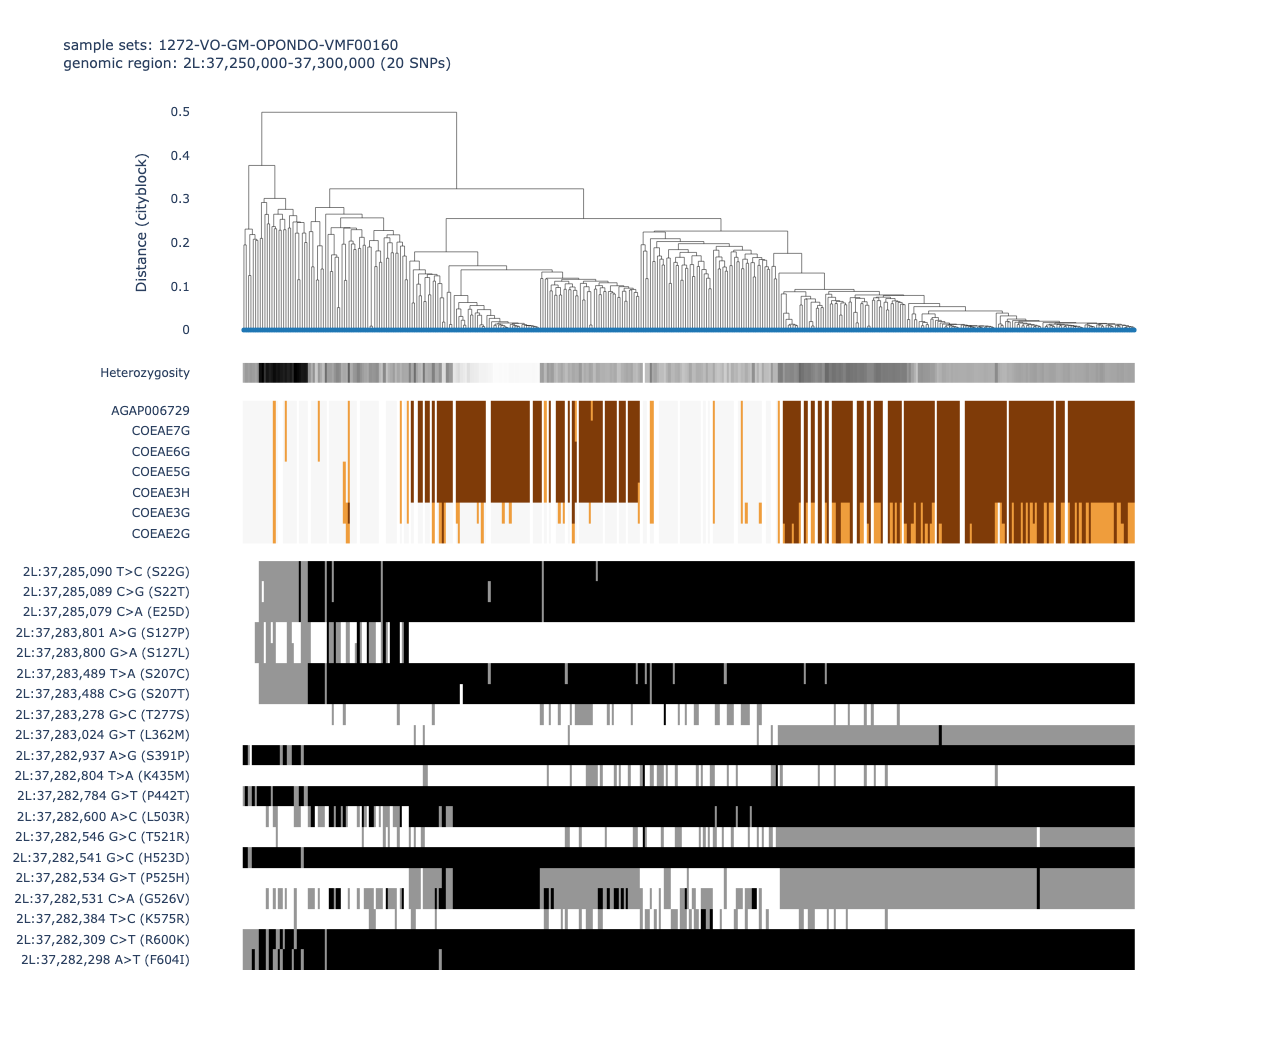

In [ ]:
ag3.plot_diplotype_clustering_advanced(
    region=coe_region,
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    cnv_region=coe_region,
    cnv_max_coverage_variance=0.8,
    snp_transcript='AGAP006723-RA'
    )

Compute modal gene copy number:   0%|          | 0/7 [00:00<?, ?it/s]

Compute SNP effects:   0%|          | 0/6738 [00:00<?, ?it/s]

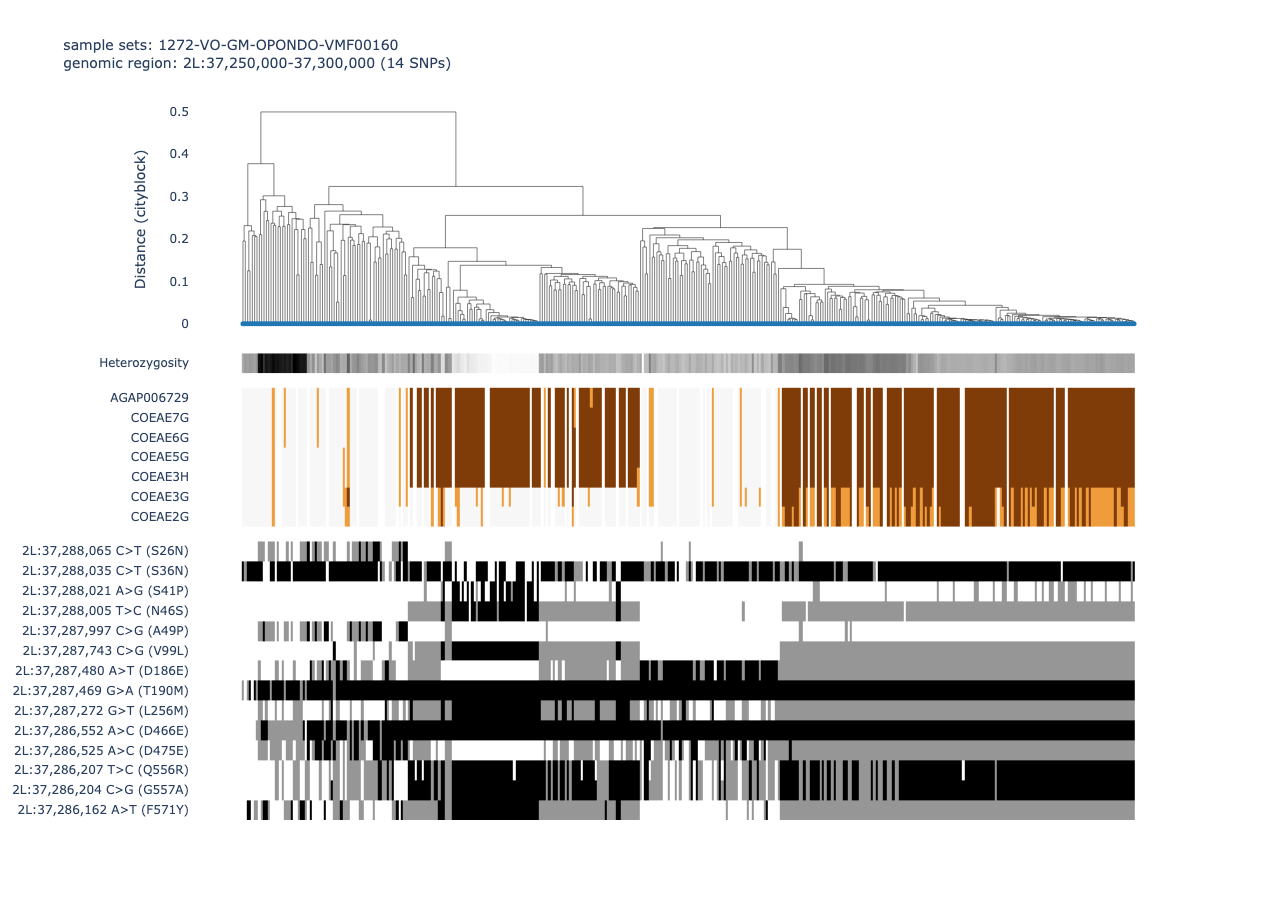

In [ ]:
ag3.plot_diplotype_clustering_advanced(
    region=coe_region,
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    cnv_region=coe_region,
    cnv_max_coverage_variance=0.8,
    snp_transcript='AGAP006724-RA'
    )

Compute modal gene copy number:   0%|          | 0/7 [00:00<?, ?it/s]

Compute SNP effects:   0%|          | 0/6108 [00:00<?, ?it/s]

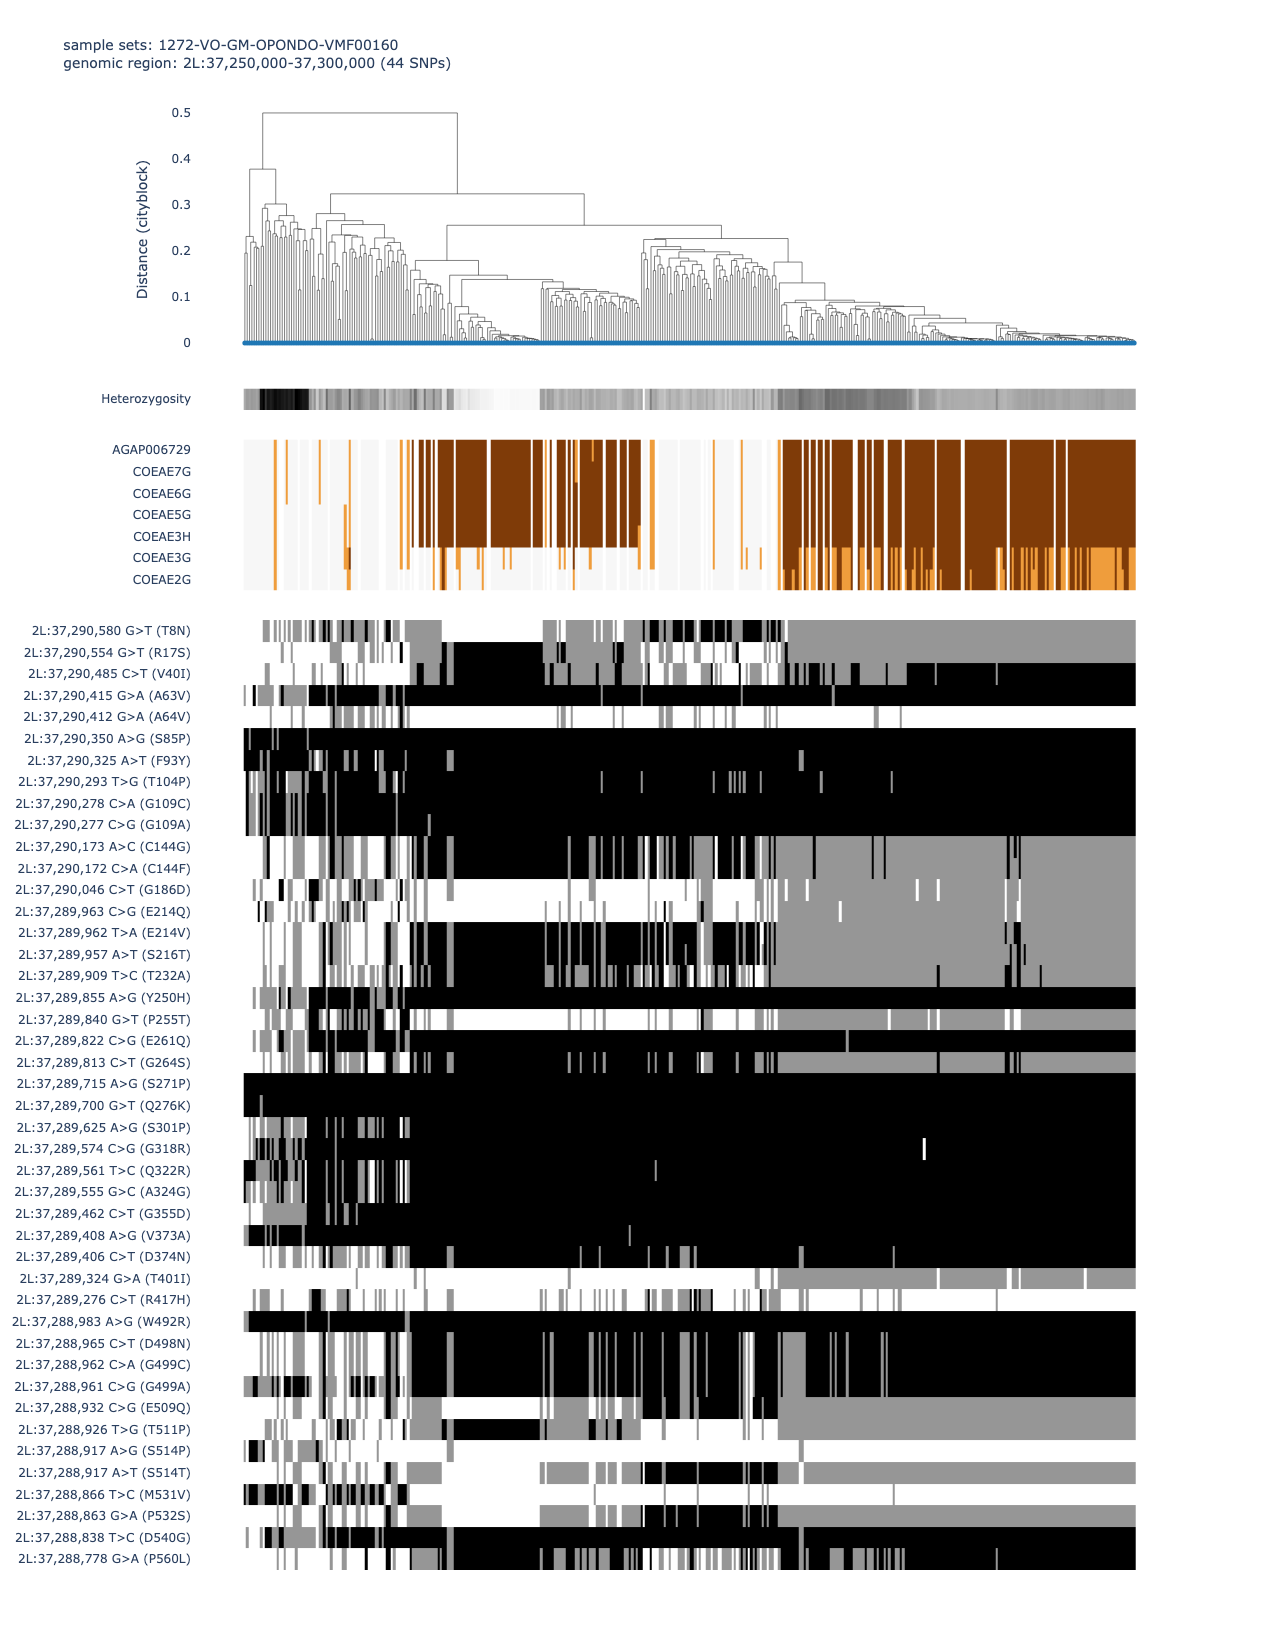

In [ ]:
ag3.plot_diplotype_clustering_advanced(
    region=coe_region,
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    cnv_region=coe_region,
    cnv_max_coverage_variance=0.8,
    snp_transcript='AGAP006725-RA'
    )

Compute modal gene copy number:   0%|          | 0/7 [00:00<?, ?it/s]

Compute SNP effects:   0%|          | 0/5880 [00:00<?, ?it/s]

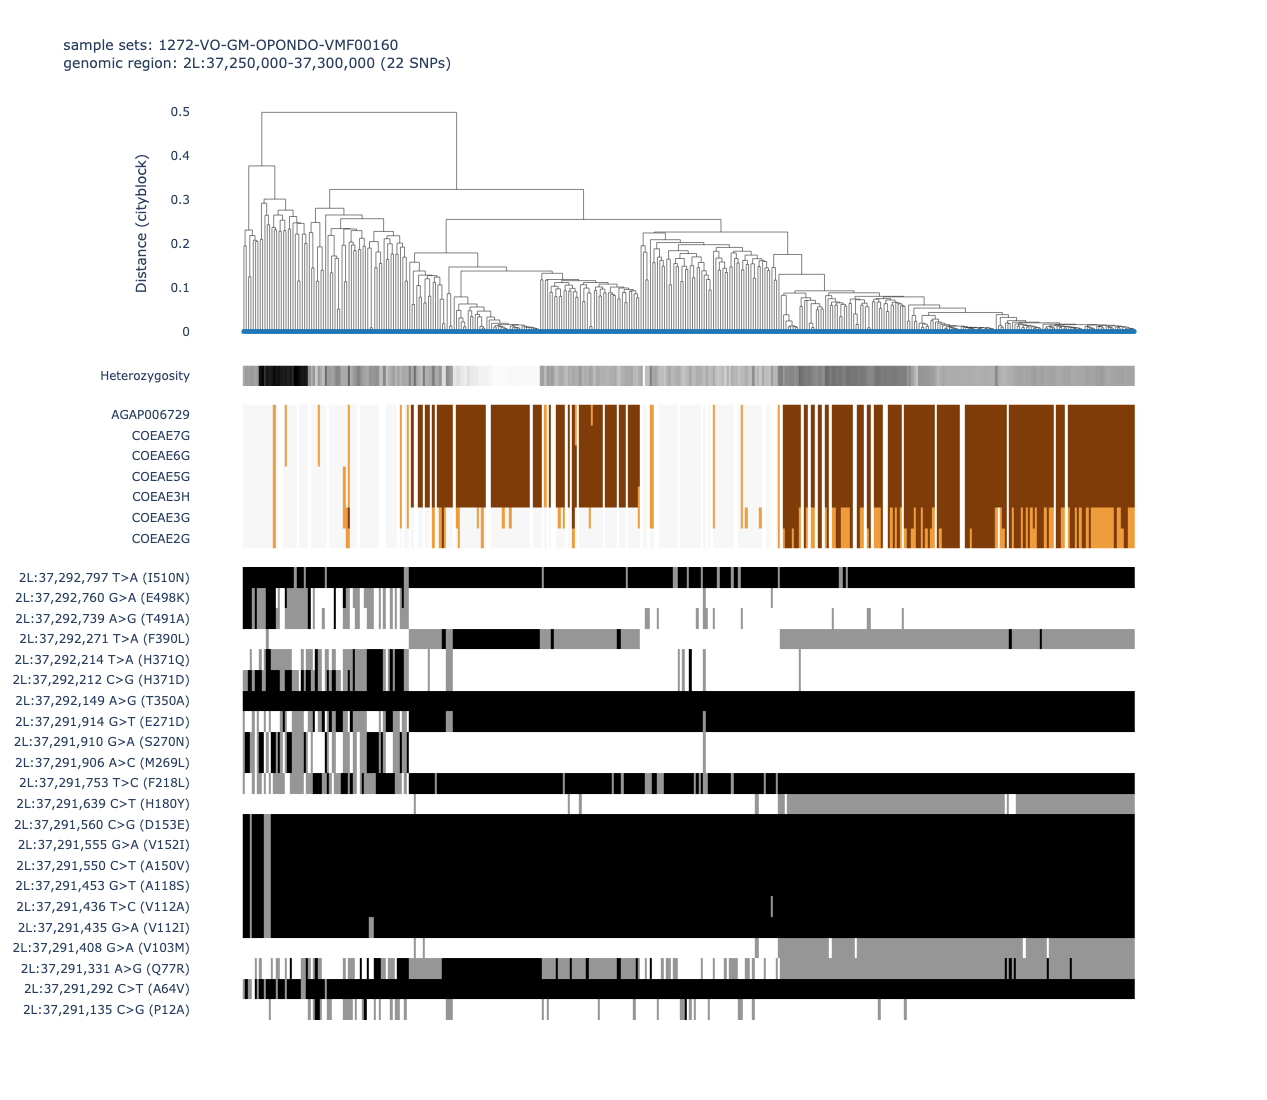

In [ ]:
ag3.plot_diplotype_clustering_advanced(
    region=coe_region,
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    cnv_region=coe_region,
    cnv_max_coverage_variance=0.8,
    snp_transcript='AGAP006726-RA'
    )

Compute modal gene copy number:   0%|          | 0/7 [00:00<?, ?it/s]

Compute SNP effects:   0%|          | 0/7605 [00:00<?, ?it/s]

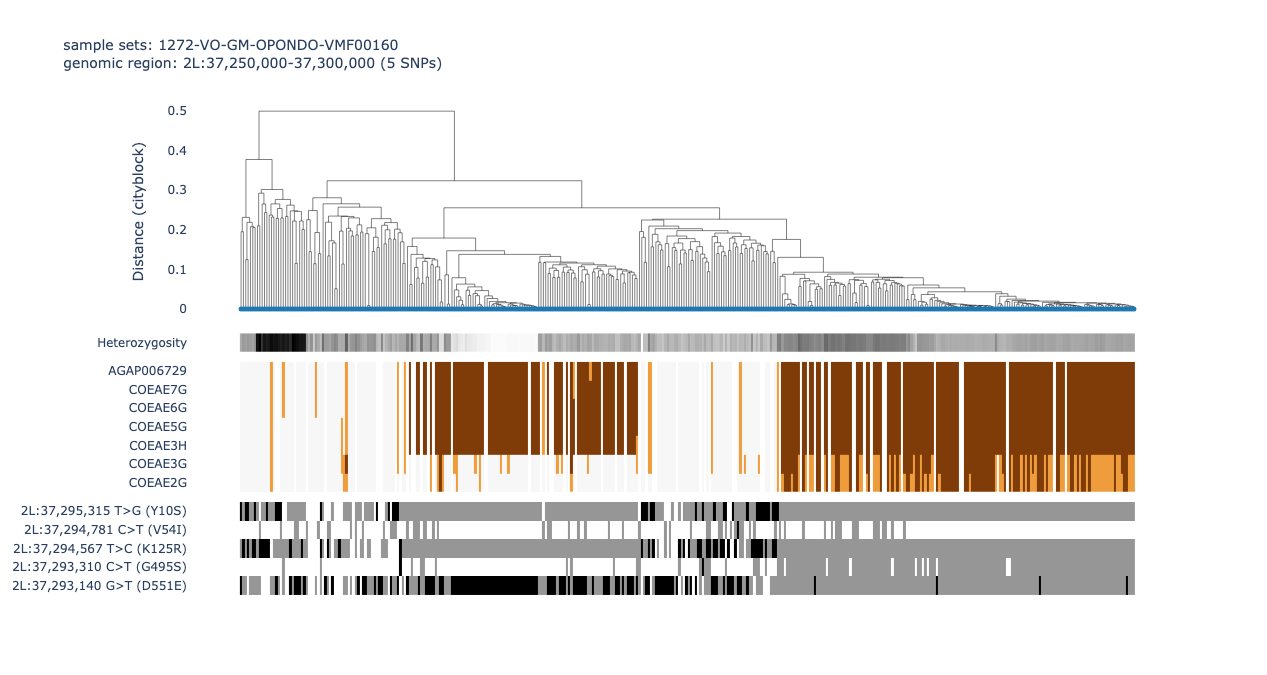

In [ ]:
ag3.plot_diplotype_clustering_advanced(
    region=coe_region,
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    cnv_region=coe_region,
    cnv_max_coverage_variance=0.8,
    snp_transcript='AGAP006727-RA'
    )

Compute modal gene copy number:   0%|          | 0/7 [00:00<?, ?it/s]

Compute SNP effects:   0%|          | 0/6126 [00:00<?, ?it/s]

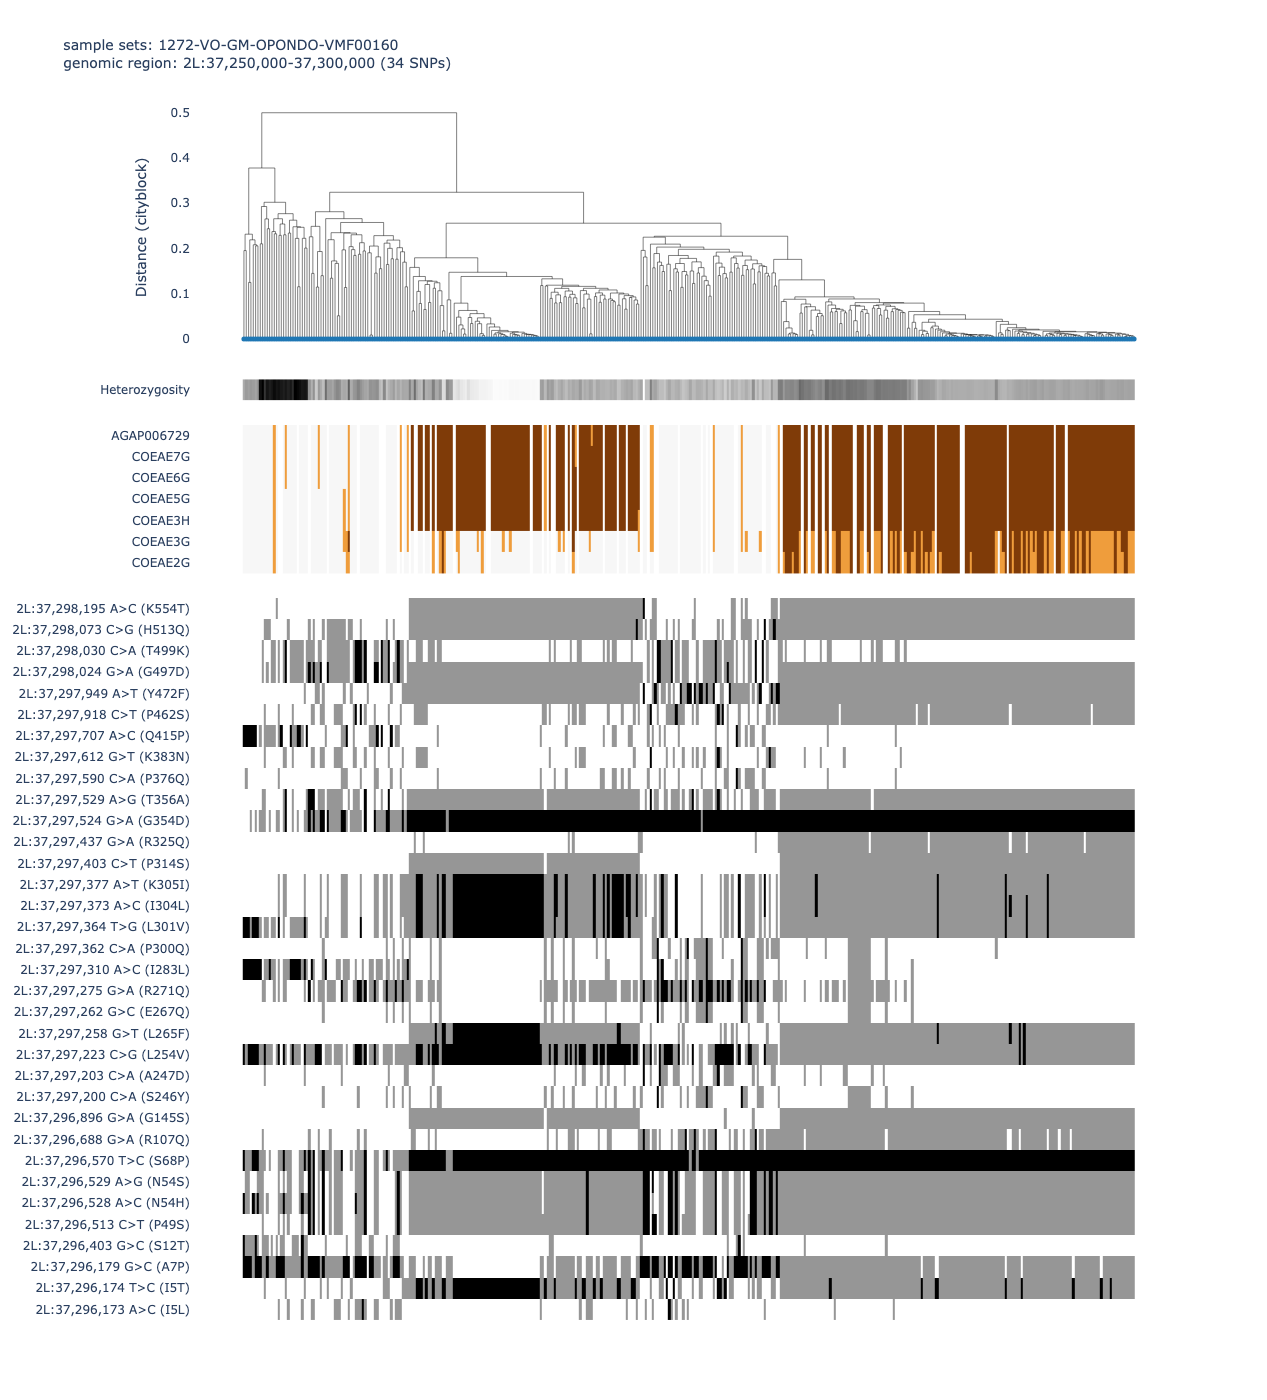

In [ ]:
ag3.plot_diplotype_clustering_advanced(
    region=coe_region,
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    cnv_region=coe_region,
    cnv_max_coverage_variance=0.8,
    snp_transcript='AGAP006728-RA'
    )

Compute modal gene copy number:   0%|          | 0/7 [00:00<?, ?it/s]

Compute SNP effects:   0%|          | 0/5031 [00:00<?, ?it/s]

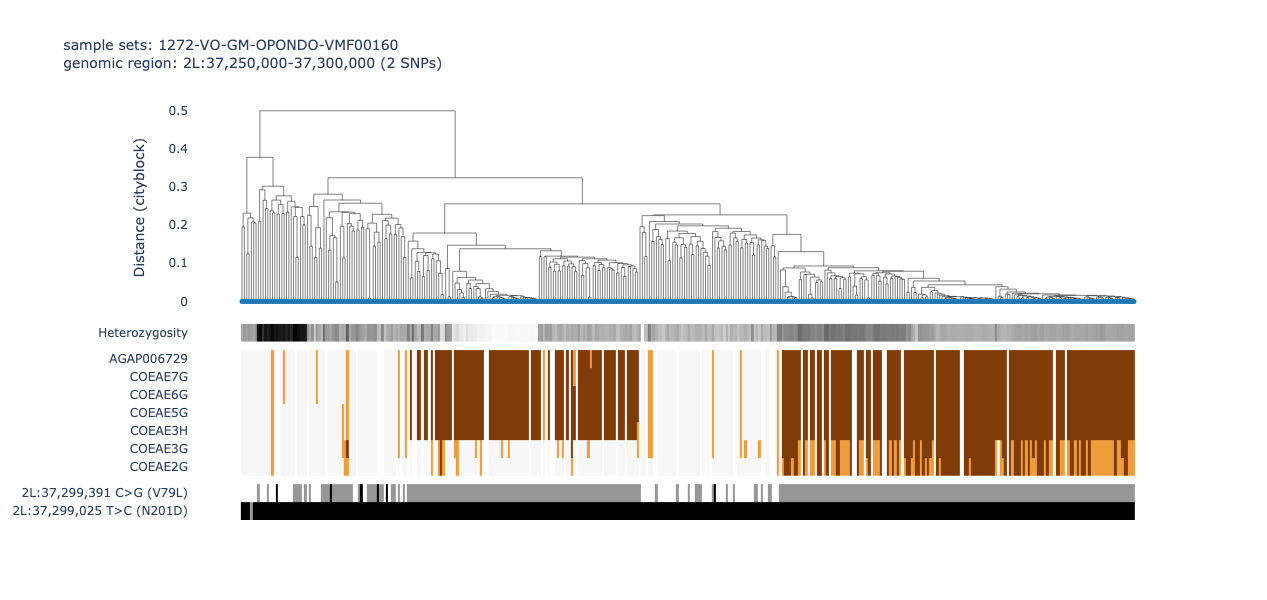

In [ ]:
ag3.plot_diplotype_clustering_advanced(
    region=coe_region,
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    cnv_region=coe_region,
    cnv_max_coverage_variance=0.8,
    snp_transcript='AGAP006729-RA'
    )

Load genotypes for distance calculation:   0%|          | 0/32 [00:00<?, ?it/s]

Load genotypes for heterozygosity calculation:   0%|          | 0/32 [00:00<?, ?it/s]

Load CNV HMM data:   0%|          | 0/42 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/1 [00:00<?, ?it/s]

Load SNP genotypes:   0%|          | 0/32 [00:00<?, ?it/s]

Compute SNP effects:   0%|          | 0/209001 [00:00<?, ?it/s]

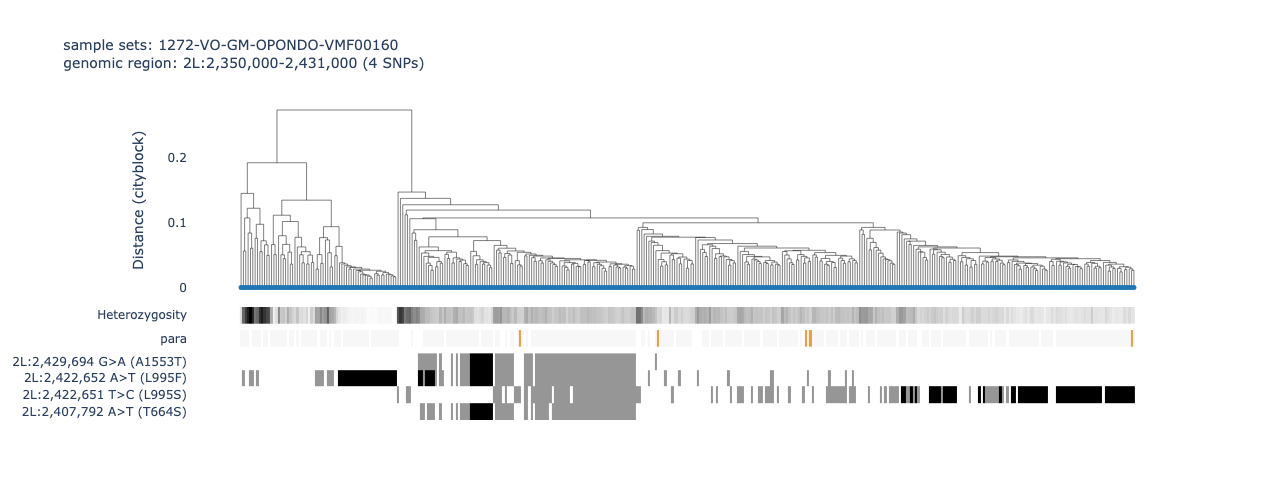

In [ ]:
ag3.plot_diplotype_clustering_advanced(
    region="2L:2,350,000-2,431,000",
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    cnv_region="2L:2,350,000-2,431,000",
    cnv_max_coverage_variance=0.8,
    snp_transcript='AGAP004707-RD'
    )